# Selección de modelos preentrenados de Hugging Face para clasificar consultas de clientes

**Caso de uso.** Cenzi es el asistente de Financiera Cenzontle (empresa ficticia). Recibe la consulta que un cliente escribe en el chat, reconoce su **intención** entre 13 posibles y devuelve una **respuesta aprobada**; si no está seguro, pasa la conversación a una persona.

**Rama de IA.** Procesamiento de lenguaje natural · clasificación de texto en español.

**Qué hace este cuaderno.** Compara tres modelos preentrenados del Hugging Face Hub, más una línea base clásica como referencia, con el mismo conjunto de prueba:

| Clave | Modelo del Hub | Estrategia | Ajuste |
|---|---|---|---|
| A | `MoritzLaurer/mDeBERTa-v3-base-mnli-xnli` | Clasificación *zero-shot* por inferencia textual (NLI) | Ninguno: no usa ejemplos etiquetados |
| B | `sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2` | *Embeddings* congelados + regresión logística | Mínimo: sólo se entrena la capa final |
| C | `intfloat/multilingual-e5-base` | *Embeddings* congelados + regresión logística | Mínimo: sólo se entrena la capa final |
| Ref. | TF-IDF + regresión logística (scikit-learn) | Línea base sin modelo preentrenado | Entrenamiento completo, en CPU |

**Cómo ejecutarlo.** `Entorno de ejecución › Cambiar tipo de entorno de ejecución › GPU T4`, y después `Entorno de ejecución › Ejecutar todo`. Tarda unos minutos. Al final se descarga `resultados.zip` con las tablas y las figuras.

## 1. Configuración de GPU
Se comprueba que el entorno tiene GPU y se fijan las semillas. Sin GPU el cuaderno funciona, pero las latencias no son comparables con las del reporte y el modelo A tarda varios minutos.

In [10]:
!nvidia-smi

Sun Oct 11 22:28:07 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   41C    P8              9W /   70W |       3MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [11]:
import os, sys, gc, json, time, random, platform, shutil, subprocess, warnings
from pathlib import Path

import numpy as np
import torch

warnings.filterwarnings("ignore", category=FutureWarning)

SEMILLA = 42
random.seed(SEMILLA); np.random.seed(SEMILLA); torch.manual_seed(SEMILLA)

HAY_GPU = torch.cuda.is_available()
DISPOSITIVO = "cuda" if HAY_GPU else "cpu"
NOMBRE_GPU = torch.cuda.get_device_name(0) if HAY_GPU else "sin GPU (CPU)"
MEMORIA_GPU_GB = round(torch.cuda.get_device_properties(0).total_memory / 2**30, 1) if HAY_GPU else None

print("Dispositivo :", DISPOSITIVO)
print("GPU         :", NOMBRE_GPU, f"({MEMORIA_GPU_GB} GB)" if HAY_GPU else "")
print("PyTorch     :", torch.__version__)
if not HAY_GPU:
    print("\nAVISO: no hay GPU. Actívala en Entorno de ejecución › Cambiar tipo de entorno de ejecución › GPU T4.")

Dispositivo : cuda
GPU         : Tesla T4 (14.6 GB)
PyTorch     : 2.11.0+cu130


## 2. Instalación de dependencias
Colab ya trae casi todo instalado; esta celda sólo agrega lo que falte. Las versiones exactas que se usaron en la corrida quedan guardadas en `results/entorno.json`.

In [12]:
%pip install -q "transformers>=4.41" "sentence-transformers>=3.0" "datasets>=2.19" "huggingface_hub>=0.23" scikit-learn pandas matplotlib sentencepiece

In [13]:
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn, transformers, datasets, sentence_transformers, huggingface_hub

from datasets import load_dataset, DatasetDict
from huggingface_hub import HfApi
from sentence_transformers import SentenceTransformer
from transformers import AutoModelForSequenceClassification, AutoTokenizer, pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             classification_report, confusion_matrix)

transformers.logging.set_verbosity_error()
pd.set_option("display.max_colwidth", 90); pd.set_option("display.width", 200)

VERSIONES = {m.__name__: m.__version__ for m in
             (torch, transformers, sentence_transformers, datasets, huggingface_hub, sklearn, pd, np, matplotlib)}
VERSIONES["python"] = platform.python_version()
pd.Series(VERSIONES, name="versión").to_frame()

,versión
torch,2.11.0+cu130
transformers,5.18.0
sentence_transformers,5.7.0
datasets,4.8.5
huggingface_hub,1.33.0
sklearn,1.6.1
pandas,2.2.3
numpy,2.1.3
matplotlib,3.10.0
python,3.13.15


## 3. Parámetros del experimento
Todo lo que se puede cambiar está en esta celda: modelos, tamaños de lote, protocolo de latencia y los umbrales con los que se decide.

Los **umbrales** vienen del caso de negocio de Cenzi y se fijan **antes** de medir, para que la elección del modelo no dependa de cómo salgan los números.

In [14]:
MODELOS = {
    "A": {
        "nombre": "mDeBERTa-v3-base NLI",
        "hub_id": "MoritzLaurer/mDeBERTa-v3-base-mnli-xnli",
        "estrategia": "zero-shot (NLI)",
        "ajuste": "ninguno",
    },
    "B": {
        "nombre": "MiniLM-L12 multilingüe",
        "hub_id": "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2",
        "estrategia": "embeddings + regresión logística",
        "ajuste": "capa final",
        "prefijo": "",
    },
    "C": {
        "nombre": "multilingual-e5-base",
        "hub_id": "intfloat/multilingual-e5-base",
        "estrategia": "embeddings + regresión logística",
        "ajuste": "capa final",
        "prefijo": "query: ",   # la ficha del modelo pide este prefijo en tareas de clasificación
    },
}

MAX_TOKENS = 64            # las consultas son cortas; 64 tokens cubren todas
LOTE_EMBEDDINGS = 64       # tamaño de lote para calcular embeddings
LOTE_NLI = 64              # pares premisa-hipótesis por lote en zero-shot
VALORES_C = (1.0, 10.0, 100.0)   # regularización de la capa final; se elige con validación

# Plantillas de hipótesis para zero-shot; se elige la mejor con validación
PLANTILLAS_NLI = ("Este mensaje trata sobre {}.", "El tema de esta consulta es {}.")

# Protocolo de latencia: una consulta a la vez, como en un chat
N_CALENTAMIENTO = 10
N_LATENCIA = 100

UMBRALES = {
    "latencia_p95_ms_max": 300,     # tiempo máximo del modelo por consulta (percentil 95)
    "acierto_respondidas_min": 0.90,  # meta del caso de negocio: acierto en lo que Cenzi responde
    "cobertura_min": 0.50,          # proporción mínima de consultas que Cenzi responde sin escalar
    "error_total_max": 0.05,        # respuestas equivocadas sobre el total de consultas
    "empate_f1": 0.01,              # diferencias de F1 menores a esto se consideran empate
}

REPO_GITHUB = ""   # opcional: URL del repositorio para clonar los datos, p. ej. "https://github.com/usuario/repo.git"

DIR_RESULTADOS = Path("results"); DIR_RESULTADOS.mkdir(exist_ok=True)

## 4. Carga del dataset
`consultas_cenzi.csv` contiene 1 495 consultas **sintéticas** en 13 intenciones (115 por intención). Se generó con `src/generar_dataset.py`: 23 frases base por intención y 5 variantes de cada una (original, sin acentos, con saludo y cierre, abreviada y con errores de tecleo).

La columna `particion` viene fijada desde el generador y se asignó **por frase base**: todas las variantes de una misma frase están en la misma partición. Así el conjunto de prueba sólo tiene redacciones que ningún modelo vio.

El cuaderno busca los CSV en `data/`; si no están, clona el repositorio (cuando `REPO_GITHUB` tiene valor) o pide subirlos.

In [15]:
ARCHIVOS = ("consultas_cenzi.csv", "respuestas_aprobadas_cenzi.csv")

def localizar_datos():
    candidatas = [Path("data"), Path("../data"), Path("."), Path("/content/data"), Path("/content")]
    for carpeta in candidatas:
        if all((carpeta / a).exists() for a in ARCHIVOS):
            return carpeta
    if REPO_GITHUB:
        destino = Path("repo_clonado")
        if not destino.exists():
            subprocess.run(["git", "clone", "--depth", "1", REPO_GITHUB, str(destino)], check=True)
        if all((destino / "data" / a).exists() for a in ARCHIVOS):
            return destino / "data"
    try:
        from google.colab import files
    except ImportError:
        raise FileNotFoundError("No se encontraron los CSV. Colócalos en la carpeta data/.")
    print("Sube los dos archivos:", ", ".join(ARCHIVOS))
    files.upload()
    carpeta = Path("data"); carpeta.mkdir(exist_ok=True)
    for a in ARCHIVOS:
        if Path(a).exists():
            shutil.move(a, carpeta / a)
    faltan = [a for a in ARCHIVOS if not (carpeta / a).exists()]
    if faltan:
        raise FileNotFoundError(f"Faltan archivos: {faltan}")
    return carpeta

DIR_DATOS = localizar_datos()
print("Datos en:", DIR_DATOS.resolve())

# Carga con la biblioteca datasets y separación por la columna 'particion'
completo = load_dataset("csv", data_files=str(DIR_DATOS / "consultas_cenzi.csv"), split="train")
dataset = DatasetDict({p: completo.filter(lambda fila, p=p: fila["particion"] == p)
                       for p in ("train", "validation", "test")})
print(dataset)
print("\nCampos:", completo.features)

Datos en: /content/data
DatasetDict({
    train: Dataset({
        features: ['id', 'texto', 'intencion', 'accion', 'frase_base', 'tipo_variante', 'particion'],
        num_rows: 845
    })
    validation: Dataset({
        features: ['id', 'texto', 'intencion', 'accion', 'frase_base', 'tipo_variante', 'particion'],
        num_rows: 260
    })
    test: Dataset({
        features: ['id', 'texto', 'intencion', 'accion', 'frase_base', 'tipo_variante', 'particion'],
        num_rows: 390
    })
})

Campos: {'id': Value('string'), 'texto': Value('string'), 'intencion': Value('string'), 'accion': Value('string'), 'frase_base': Value('string'), 'tipo_variante': Value('string'), 'particion': Value('string')}


In [16]:
catalogo = pd.read_csv(DIR_DATOS / "respuestas_aprobadas_cenzi.csv")
ETIQUETAS = catalogo["intencion"].tolist()                 # orden fijo de las 13 clases
ID_DE = {etiqueta: i for i, etiqueta in enumerate(ETIQUETAS)}
DESCRIPCIONES = catalogo["descripcion"].tolist()           # texto de cada clase para zero-shot
ACCION_DE = dict(zip(catalogo["intencion"], catalogo["accion"]))
RESPUESTA_DE = dict(zip(catalogo["intencion"], catalogo["respuesta_aprobada"]))

datos = {p: dataset[p].to_pandas() for p in dataset}
X = {p: datos[p]["texto"].astype(str).tolist() for p in datos}
y = {p: datos[p]["intencion"].map(ID_DE).to_numpy() for p in datos}

# Comprobaciones: clases completas y ninguna frase base repartida entre particiones
assert all(set(np.unique(y[p])) == set(range(len(ETIQUETAS))) for p in y), "faltan clases en alguna partición"
grupos = {p: set(datos[p]["frase_base"]) for p in datos}
assert not (grupos["train"] & grupos["test"]) and not (grupos["train"] & grupos["validation"]) \
       and not (grupos["validation"] & grupos["test"]), "hay fuga de frases base entre particiones"

resumen_datos = pd.DataFrame({p: datos[p]["intencion"].value_counts().reindex(ETIQUETAS) for p in datos})
resumen_datos.loc["TOTAL"] = resumen_datos.sum()
display(resumen_datos)
display(datos["test"].groupby("tipo_variante").head(1)[["texto", "intencion", "tipo_variante"]])
display(catalogo[["intencion", "accion", "descripcion"]])

,train,validation,test
intencion,,,
saldo,65,20,30
fecha_pago,65,20,30
formas_pago,65,20,30
pago_no_reflejado,65,20,30
requisitos,65,20,30
estatus_solicitud,65,20,30
sucursales_horarios,65,20,30
tasas_comisiones,65,20,30
liquidacion_anticipada,65,20,30


,texto,intencion,tipo_variante
0,¿Cuánto debo de mi crédito?,saldo,original
1,cuanto debo de mi credito?,saldo,sin_acentos
2,"Hola buen día, ¿cuánto debo de mi crédito? ayuda por favor",saldo,saludo_cierre
3,cuanto debo de mi credito,saldo,abreviada
4,cuanto debo de mi crdito?,saldo,errores_tecleo


,intencion,accion,descripcion
0,saldo,responder,el saldo o adeudo del crédito
1,fecha_pago,responder,la fecha de pago o de vencimiento
2,formas_pago,responder,las formas y lugares para pagar
3,pago_no_reflejado,responder,un pago realizado que no aparece reflejado
4,requisitos,responder,los requisitos y documentos para solicitar un crédito
5,estatus_solicitud,responder,el estatus de una solicitud de crédito
6,sucursales_horarios,responder,la ubicación de sucursales y los horarios de atención
7,tasas_comisiones,responder,"las tasas de interés, comisiones y costos del crédito"
8,liquidacion_anticipada,responder,liquidar el crédito por adelantado o abonar a capital
9,actualizacion_datos,responder,actualizar datos personales o de contacto


## 5. Funciones de evaluación
Todos los modelos se exponen con la misma interfaz: una función `predecir_proba(textos)` que devuelve una matriz de probabilidades (consultas × 13 intenciones). Con eso, métricas y latencia se calculan con el mismo código para todos.

- **Métricas:** accuracy, y precision, recall y F1 en promedio macro (cada intención pesa igual) y ponderado.
- **Intervalo de confianza:** *bootstrap* de 1 000 remuestreos **por frase base**, porque las cinco variantes de una frase no son independientes.
- **Latencia:** una consulta a la vez, 10 de calentamiento y 100 medidas; se reportan mediana y percentil 95. En GPU se sincroniza antes de leer el reloj.
- **Rendimiento:** consultas por segundo procesando el conjunto de prueba por lotes.
- **Memoria:** pico de memoria de GPU atribuible al modelo.

In [17]:
RESULTADOS = {}    # métricas y metadatos por modelo
PREDICTORES = {}   # función predecir_proba por modelo
PROBAS = {}        # probabilidades en validación y prueba por modelo

def sincronizar():
    if HAY_GPU:
        torch.cuda.synchronize()

def memoria_asignada_mb():
    return torch.cuda.memory_allocated() / 2**20 if HAY_GPU else 0.0

def reiniciar_pico():
    if HAY_GPU:
        gc.collect(); torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats()

def pico_mb():
    return torch.cuda.max_memory_allocated() / 2**20 if HAY_GPU else None

def calcular_metricas(y_real, y_pred):
    p_m, r_m, f_m, _ = precision_recall_fscore_support(y_real, y_pred, average="macro", zero_division=0)
    p_w, r_w, f_w, _ = precision_recall_fscore_support(y_real, y_pred, average="weighted", zero_division=0)
    return {"accuracy": accuracy_score(y_real, y_pred),
            "precision_macro": p_m, "recall_macro": r_m, "f1_macro": f_m,
            "precision_ponderada": p_w, "recall_ponderado": r_w, "f1_ponderado": f_w}

def intervalo_bootstrap(y_real, y_pred, grupos, n=1000, semilla=SEMILLA):
    # IC 95 % de accuracy y F1 macro remuestreando frases base completas
    rng = np.random.default_rng(semilla)
    grupos = np.asarray(grupos)
    indices = [np.flatnonzero(grupos == g) for g in np.unique(grupos)]
    accs, f1s = [], []
    for _ in range(n):
        idx = np.concatenate([indices[i] for i in rng.integers(0, len(indices), len(indices))])
        accs.append(accuracy_score(y_real[idx], y_pred[idx]))
        f1s.append(precision_recall_fscore_support(y_real[idx], y_pred[idx], average="macro", zero_division=0)[2])
    return {"accuracy_ic95": [float(np.percentile(accs, 2.5)), float(np.percentile(accs, 97.5))],
            "f1_macro_ic95": [float(np.percentile(f1s, 2.5)), float(np.percentile(f1s, 97.5))]}

def medir_latencia(predecir_proba, textos):
    for t in textos[:N_CALENTAMIENTO]:
        predecir_proba([t])
    tiempos = []
    for t in textos[:N_LATENCIA]:
        sincronizar(); t0 = time.perf_counter()
        predecir_proba([t])
        sincronizar(); tiempos.append((time.perf_counter() - t0) * 1000)
    return {"latencia_media_ms": float(np.mean(tiempos)), "latencia_p50_ms": float(np.percentile(tiempos, 50)),
            "latencia_p95_ms": float(np.percentile(tiempos, 95))}

def elegir_umbral(y_real, proba, objetivo):
    # Umbral de confianza más bajo que alcanza el acierto objetivo en lo respondido (máxima cobertura)
    confianza, pred = proba.max(axis=1), proba.argmax(axis=1)
    mejor = None
    for u in np.round(np.arange(0.0, 1.0, 0.01), 2):
        respondidas = confianza >= u
        if respondidas.sum() < 20:     # con menos de 20 respuestas el acierto no es fiable
            break
        acierto = float((pred[respondidas] == y_real[respondidas]).mean())
        if acierto >= objetivo:
            return float(u), True
        if mejor is None or acierto > mejor[1]:
            mejor = (float(u), acierto)
    return mejor[0], False   # ningún umbral alcanza el objetivo: se devuelve el de mayor acierto

def aplicar_umbral(y_real, proba, umbral):
    confianza, pred = proba.max(axis=1), proba.argmax(axis=1)
    respondidas = confianza >= umbral
    correctas = pred == y_real
    return {"cobertura": float(respondidas.mean()),
            "acierto_respondidas": float(correctas[respondidas].mean()) if respondidas.any() else float("nan"),
            "error_total": float((respondidas & ~correctas).mean())}

def info_del_hub(hub_id):
    # Licencia, tarea, descargas y tamaño de los pesos según el Hub (None si no hay conexión)
    info = {"licencia": None, "tarea_hub": None, "descargas_mes": None, "pesos_mb": None}
    try:
        m = HfApi().model_info(hub_id, files_metadata=True)
        info["licencia"] = next((t.split(":", 1)[1] for t in (m.tags or []) if t.startswith("license:")), None)
        info["tarea_hub"] = m.pipeline_tag
        info["descargas_mes"] = m.downloads
        tamanos = {s.rfilename: s.size for s in (m.siblings or []) if s.size}
        for archivo in ("model.safetensors", "pytorch_model.bin"):
            if archivo in tamanos:
                info["pesos_mb"] = round(tamanos[archivo] / 2**20, 1); break
    except Exception as e:
        print(f"  (no se pudo consultar el Hub para {hub_id}: {type(e).__name__})")
    return info

def evaluar(clave, nombre, predecir_proba, extra):
    # Evalúa un modelo en validación y prueba y guarda todo en RESULTADOS
    proba_val = predecir_proba(X["validation"])
    sincronizar(); t0 = time.perf_counter()
    proba_test = predecir_proba(X["test"])
    sincronizar(); segundos = time.perf_counter() - t0

    pred_val, pred_test = proba_val.argmax(axis=1), proba_test.argmax(axis=1)
    r = {"clave": clave, "modelo": nombre, **extra}
    r.update({f"val_{k}": v for k, v in calcular_metricas(y["validation"], pred_val).items()})
    r.update(calcular_metricas(y["test"], pred_test))
    r.update(intervalo_bootstrap(y["test"], pred_test, datos["test"]["frase_base"].to_numpy()))
    r["consultas_por_segundo"] = len(X["test"]) / segundos
    r["segundos_gpu_por_1000"] = 1000 * segundos / len(X["test"])
    r.update(medir_latencia(predecir_proba, X["test"]))

    umbral, alcanza = elegir_umbral(y["validation"], proba_val, UMBRALES["acierto_respondidas_min"])
    r["umbral_confianza"], r["umbral_alcanza_objetivo_val"] = umbral, alcanza
    r.update({f"val_{k}": v for k, v in aplicar_umbral(y["validation"], proba_val, umbral).items()})
    r.update(aplicar_umbral(y["test"], proba_test, umbral))

    RESULTADOS[clave], PREDICTORES[clave] = r, predecir_proba
    PROBAS[clave] = {"validation": proba_val, "test": proba_test}
    return r

def conclusion_parcial(clave):
    r = RESULTADOS[clave]
    lo, hi = r["f1_macro_ic95"]
    print(f"── Conclusión parcial · {r['modelo']} ──")
    print(f"Prueba: accuracy {r['accuracy']:.3f} · precision {r['precision_macro']:.3f} · "
          f"recall {r['recall_macro']:.3f} · F1 macro {r['f1_macro']:.3f} (IC 95 %: {lo:.3f}–{hi:.3f})")
    print(f"Latencia por consulta: mediana {r['latencia_p50_ms']:.1f} ms · p95 {r['latencia_p95_ms']:.1f} ms · "
          f"{r['consultas_por_segundo']:.0f} consultas/s por lotes")
    ok_lat = r["latencia_p95_ms"] <= UMBRALES["latencia_p95_ms_max"]
    print(f"Umbral de latencia (p95 ≤ {UMBRALES['latencia_p95_ms_max']} ms): {'CUMPLE' if ok_lat else 'NO CUMPLE'}")
    print(f"Con umbral de confianza {r['umbral_confianza']:.2f} (elegido en validación): responde "
          f"{r['cobertura']:.1%} de las consultas con {r['acierto_respondidas']:.1%} de acierto; "
          f"respuestas equivocadas sobre el total: {r['error_total']:.1%}")
    if "REF" in RESULTADOS and clave != "REF":
        d = r["f1_macro"] - RESULTADOS["REF"]["f1_macro"]
        print(f"Frente a la línea base TF-IDF: {d:+.3f} de F1 macro")

## 6. Línea base de referencia: TF-IDF + regresión logística
No es un modelo preentrenado. Se incluye para responder una pregunta previa: **¿un modelo del Hub mejora lo que ya se consigue con un método clásico que corre en CPU?** Si la respuesta fuera no, la complejidad adicional no se justificaría.

In [18]:
t0 = time.perf_counter()
linea_base = make_pipeline(
    TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), sublinear_tf=True, lowercase=True),
    LogisticRegression(C=10.0, max_iter=3000),
).fit(X["train"], y["train"])
t_ajuste = time.perf_counter() - t0

evaluar("REF", "TF-IDF + reg. logística", lambda textos: linea_base.predict_proba(list(textos)), {
    "hub_id": "— (scikit-learn)", "estrategia": "línea base clásica", "ajuste": "entrenamiento completo",
    "dispositivo": "cpu", "parametros_millones": linea_base[-1].coef_.size / 1e6,
    "licencia": "BSD-3-Clause", "tarea_hub": None, "descargas_mes": None, "pesos_mb": None,
    "memoria_gpu_mb": 0.0, "segundos_ajuste": t_ajuste,
})
conclusion_parcial("REF")

── Conclusión parcial · TF-IDF + reg. logística ──
Prueba: accuracy 0.636 · precision 0.653 · recall 0.636 · F1 macro 0.634 (IC 95 %: 0.512–0.707)
Latencia por consulta: mediana 3.9 ms · p95 7.9 ms · 2475 consultas/s por lotes
Umbral de latencia (p95 ≤ 300 ms): CUMPLE
Con umbral de confianza 0.63 (elegido en validación): responde 22.6% de las consultas con 90.9% de acierto; respuestas equivocadas sobre el total: 2.1%


## 7. Modelo A · Clasificación *zero-shot* con mDeBERTa-v3 (NLI)
El modelo fue entrenado para decidir si una hipótesis se deduce de una premisa. Aquí la premisa es la consulta del cliente y se prueban 13 hipótesis, una por intención («Este mensaje trata sobre *las formas y lugares para pagar*.»). Gana la hipótesis con mayor probabilidad de implicación.

**Ajuste mínimo:** no se entrena nada. Las únicas decisiones son la redacción de la descripción de cada intención y la plantilla de la hipótesis, que se elige con el conjunto de validación.

Los pesos del repositorio están en media precisión (float16); se convierten a float32 porque DeBERTa-v3 es numéricamente inestable en float16.

In [19]:
cfg = MODELOS["A"]
reiniciar_pico(); mem_antes = memoria_asignada_mb()

tok_a = AutoTokenizer.from_pretrained(cfg["hub_id"])
modelo_a = AutoModelForSequenceClassification.from_pretrained(cfg["hub_id"]).float().eval()
clasificador_zs = pipeline("zero-shot-classification", model=modelo_a, tokenizer=tok_a,
                           device=0 if HAY_GPU else -1)

print("Etiquetas NLI del modelo:", modelo_a.config.id2label)
assert any(str(e).lower().startswith("entail") for e in modelo_a.config.label2id), \
    "el modelo no declara la etiqueta 'entailment'; el pipeline zero-shot no sería fiable"

INDICE_DESCRIPCION = {d: i for i, d in enumerate(DESCRIPCIONES)}

def crear_predictor_zs(plantilla):
    def predecir_proba(textos):
        textos = list(textos)
        salidas = clasificador_zs(textos, candidate_labels=DESCRIPCIONES, hypothesis_template=plantilla,
                                  multi_label=False, batch_size=LOTE_NLI)
        if isinstance(salidas, dict):
            salidas = [salidas]
        proba = np.zeros((len(salidas), len(ETIQUETAS)))
        for i, s in enumerate(salidas):
            for descripcion, puntaje in zip(s["labels"], s["scores"]):
                proba[i, INDICE_DESCRIPCION[descripcion]] = puntaje
        return proba
    return predecir_proba

# Decisión de ajuste mínimo: se elige la plantilla con mejor F1 macro en validación
f1_por_plantilla = {}
for plantilla in PLANTILLAS_NLI:
    pred = crear_predictor_zs(plantilla)(X["validation"]).argmax(axis=1)
    f1_por_plantilla[plantilla] = calcular_metricas(y["validation"], pred)["f1_macro"]
    print(f"  plantilla «{plantilla}» → F1 macro en validación: {f1_por_plantilla[plantilla]:.3f}")
PLANTILLA_ELEGIDA = max(f1_por_plantilla, key=f1_por_plantilla.get)
print("Plantilla elegida:", PLANTILLA_ELEGIDA)

evaluar("A", cfg["nombre"], crear_predictor_zs(PLANTILLA_ELEGIDA), {
    "hub_id": cfg["hub_id"], "estrategia": cfg["estrategia"], "ajuste": cfg["ajuste"],
    "dispositivo": DISPOSITIVO, "parametros_millones": sum(p.numel() for p in modelo_a.parameters()) / 1e6,
    **info_del_hub(cfg["hub_id"]),
    "memoria_gpu_mb": (pico_mb() - mem_antes) if HAY_GPU else None, "segundos_ajuste": 0.0,
    "detalle_ajuste": f"plantilla: {PLANTILLA_ELEGIDA}",
})
conclusion_parcial("A")

config.json:   0%|          | 0.00/1.07k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/1.26k [00:00<?, ?B/s]

spm.model: reconstructing file:   0%|          |  0.00B / 4.31MB            

spm.model: downloading bytes:           |  0.00B            

tokenizer.json: reconstructing file:   0%|          |  0.00B / 16.3MB            

...

special_tokens_map.json:   0%|          | 0.00/286 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  558MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

Etiquetas NLI del modelo: {0: 'entailment', 1: 'neutral', 2: 'contradiction'}
  plantilla «Este mensaje trata sobre {}.» → F1 macro en validación: 0.277
  plantilla «El tema de esta consulta es {}.» → F1 macro en validación: 0.301
Plantilla elegida: El tema de esta consulta es {}.
── Conclusión parcial · mDeBERTa-v3-base NLI ──
Prueba: accuracy 0.297 · precision 0.412 · recall 0.297 · F1 macro 0.281 (IC 95 %: 0.197–0.340)
Latencia por consulta: mediana 49.8 ms · p95 56.2 ms · 22 consultas/s por lotes
Umbral de latencia (p95 ≤ 300 ms): CUMPLE
Con umbral de confianza 0.91 (elegido en validación): responde 8.7% de las consultas con 73.5% de acierto; respuestas equivocadas sobre el total: 2.3%
Frente a la línea base TF-IDF: -0.353 de F1 macro


**Lectura del modelo A.** Su ventaja es operativa: no necesita ejemplos etiquetados, y agregar o renombrar una intención sólo requiere cambiar un texto. Su costo también es estructural: cada consulta se compara contra las 13 hipótesis, así que el cómputo crece con el número de intenciones. La línea de arriba indica si esa flexibilidad alcanza los umbrales del caso.

## 8. Modelos B y C · *Embeddings* congelados + regresión logística
El modelo preentrenado convierte cada consulta en un vector y **no se modifica**. Sobre esos vectores se entrena una regresión logística con las 845 consultas de entrenamiento.

**Ajuste mínimo:** sólo se aprende la capa final (13 × dimensión del vector, más los sesgos). El único hiperparámetro, la regularización `C`, se elige con validación entre tres valores.

In [20]:
def evaluar_embeddings(clave):
    cfg = MODELOS[clave]
    reiniciar_pico(); mem_antes = memoria_asignada_mb()

    codificador = SentenceTransformer(cfg["hub_id"], device=DISPOSITIVO)
    codificador.max_seq_length = MAX_TOKENS

    def embeber(textos):
        return codificador.encode([cfg["prefijo"] + t for t in textos], batch_size=LOTE_EMBEDDINGS,
                                  normalize_embeddings=True, convert_to_numpy=True, show_progress_bar=False)

    sincronizar(); t0 = time.perf_counter()
    E_train = embeber(X["train"])
    E_val = embeber(X["validation"])

    # Decisión de ajuste mínimo: regularización de la capa final, elegida con validación
    f1_por_c = {}
    for c in VALORES_C:
        cabeza = LogisticRegression(C=c, max_iter=3000).fit(E_train, y["train"])
        f1_por_c[c] = calcular_metricas(y["validation"], cabeza.predict(E_val))["f1_macro"]
    c_elegido = max(f1_por_c, key=f1_por_c.get)
    cabeza = LogisticRegression(C=c_elegido, max_iter=3000).fit(E_train, y["train"])
    sincronizar(); t_ajuste = time.perf_counter() - t0
    print(f"F1 macro en validación por C: { {c: round(v, 3) for c, v in f1_por_c.items()} } → C = {c_elegido}")

    def predecir_proba(textos):
        return cabeza.predict_proba(embeber(list(textos)))

    evaluar(clave, cfg["nombre"], predecir_proba, {
        "hub_id": cfg["hub_id"], "estrategia": cfg["estrategia"], "ajuste": cfg["ajuste"],
        "dispositivo": DISPOSITIVO,
        "parametros_millones": sum(p.numel() for p in codificador.parameters()) / 1e6,
        **info_del_hub(cfg["hub_id"]),
        "memoria_gpu_mb": (pico_mb() - mem_antes) if HAY_GPU else None, "segundos_ajuste": t_ajuste,
        "detalle_ajuste": f"C = {c_elegido}; vector de {E_train.shape[1]} dimensiones",
    })
    conclusion_parcial(clave)

evaluar_embeddings("B")

modules.json:   0%|          | 0.00/229 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/122 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/3.89k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/645 [00:00<?, ?B/s]

...

tokenizer.json: reconstructing file:   0%|          |  0.00B / 9.08MB            

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

F1 macro en validación por C: {1.0: 0.607, 10.0: 0.636, 100.0: 0.594} → C = 10.0
── Conclusión parcial · MiniLM-L12 multilingüe ──
Prueba: accuracy 0.651 · precision 0.667 · recall 0.651 · F1 macro 0.649 (IC 95 %: 0.555–0.706)
Latencia por consulta: mediana 11.4 ms · p95 13.3 ms · 1548 consultas/s por lotes
Umbral de latencia (p95 ≤ 300 ms): CUMPLE
Con umbral de confianza 0.74 (elegido en validación): responde 36.7% de las consultas con 94.4% de acierto; respuestas equivocadas sobre el total: 2.1%
Frente a la línea base TF-IDF: +0.015 de F1 macro


**Lectura del modelo B.** Es el más pequeño de los tres (12 capas con vectores de 384 dimensiones). Si sus métricas quedan cerca de las del modelo C, la eficiencia inclina la decisión a su favor.

In [21]:
evaluar_embeddings("C")

modules.json:   0%|          | 0.00/387 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/179k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/57.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/694 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.11GB            

...

tokenizer.json: reconstructing file:   0%|          |  0.00B / 17.1MB            

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/280 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/200 [00:00<?, ?B/s]

F1 macro en validación por C: {1.0: 0.748, 10.0: 0.778, 100.0: 0.748} → C = 10.0
── Conclusión parcial · multilingual-e5-base ──
Prueba: accuracy 0.795 · precision 0.806 · recall 0.795 · F1 macro 0.791 (IC 95 %: 0.692–0.851)
Latencia por consulta: mediana 16.2 ms · p95 20.2 ms · 812 consultas/s por lotes
Umbral de latencia (p95 ≤ 300 ms): CUMPLE
Con umbral de confianza 0.39 (elegido en validación): responde 61.0% de las consultas con 95.8% de acierto; respuestas equivocadas sobre el total: 2.6%
Frente a la línea base TF-IDF: +0.157 de F1 macro


**Lectura del modelo C.** Tiene más del doble de parámetros que B y vectores de 768 dimensiones. La pregunta es si ese tamaño adicional se traduce en una mejora de F1 mayor que la incertidumbre de la medición (intervalo de confianza).

## 9. Tabla comparativa
Métricas en el conjunto de **prueba** (390 consultas, 30 por intención, con redacciones no vistas).

In [22]:
ORDEN = [c for c in ("A", "B", "C", "REF") if c in RESULTADOS]
tabla = pd.DataFrame([RESULTADOS[c] for c in ORDEN]).set_index("clave")

columnas_resumen = ["modelo", "estrategia", "parametros_millones", "pesos_mb", "licencia",
                    "accuracy", "precision_macro", "recall_macro", "f1_macro",
                    "latencia_p50_ms", "latencia_p95_ms", "consultas_por_segundo",
                    "memoria_gpu_mb", "segundos_ajuste"]
resumen = tabla[columnas_resumen].copy()
display(resumen.style.format({
    "parametros_millones": "{:.1f}", "pesos_mb": "{:.0f}", "accuracy": "{:.3f}", "precision_macro": "{:.3f}",
    "recall_macro": "{:.3f}", "f1_macro": "{:.3f}", "latencia_p50_ms": "{:.1f}", "latencia_p95_ms": "{:.1f}",
    "consultas_por_segundo": "{:.0f}", "memoria_gpu_mb": "{:.0f}", "segundos_ajuste": "{:.1f}"}, na_rep="—"))

tabla.to_csv(DIR_RESULTADOS / "tabla_comparativa.csv", encoding="utf-8")

,modelo,estrategia,parametros_millones,pesos_mb,licencia,accuracy,precision_macro,recall_macro,f1_macro,latencia_p50_ms,latencia_p95_ms,consultas_por_segundo,memoria_gpu_mb,segundos_ajuste
clave,,,,,,,,,,,,,,
A,mDeBERTa-v3-base NLI,zero-shot (NLI),278.8,532,mit,0.297,0.412,0.297,0.281,49.8,56.2,22,1527,0.0
B,MiniLM-L12 multilingüe,embeddings + regresión logística,117.7,449,apache-2.0,0.651,0.667,0.651,0.649,11.4,13.3,1548,476,3.1
C,multilingual-e5-base,embeddings + regresión logística,278.0,1061,mit,0.795,0.806,0.795,0.791,16.2,20.2,812,1121,3.3
REF,TF-IDF + reg. logística,línea base clásica,0.1,—,BSD-3-Clause,0.636,0.653,0.636,0.634,3.9,7.9,2475,0,4.0


## 10. Desempeño por intención y matrices de confusión
El promedio puede ocultar intenciones concretas que fallan. Importa sobre todo `queja_aclaracion` y `hablar_asesor`, porque son las que deben llegar a una persona.

In [23]:
filas = []
for c in ORDEN:
    pred = PROBAS[c]["test"].argmax(axis=1)
    informe = classification_report(y["test"], pred, labels=list(range(len(ETIQUETAS))), target_names=ETIQUETAS,
                                    output_dict=True, zero_division=0)
    for etiqueta in ETIQUETAS:
        filas.append({"clave": c, "intencion": etiqueta, "precision": informe[etiqueta]["precision"],
                      "recall": informe[etiqueta]["recall"], "f1": informe[etiqueta]["f1-score"],
                      "soporte": int(informe[etiqueta]["support"])})
por_clase = pd.DataFrame(filas)
por_clase.to_csv(DIR_RESULTADOS / "metricas_por_clase.csv", index=False, encoding="utf-8")

f1_por_clase = por_clase.pivot(index="intencion", columns="clave", values="f1").reindex(ETIQUETAS)[ORDEN]
display(f1_por_clase.style.format("{:.2f}").background_gradient(cmap="Blues", vmin=0, vmax=1))

clave,A,B,C,REF
intencion,,,,
saldo,0.11,0.81,0.82,0.67
fecha_pago,0.35,0.74,0.83,0.67
formas_pago,0.57,0.55,0.75,0.58
pago_no_reflejado,0.47,0.50,0.73,0.49
requisitos,0.00,0.56,0.75,0.52
estatus_solicitud,0.17,0.49,0.67,0.39
sucursales_horarios,0.33,0.79,0.88,0.95
tasas_comisiones,0.12,0.58,0.73,0.70
liquidacion_anticipada,0.06,0.56,0.78,0.67


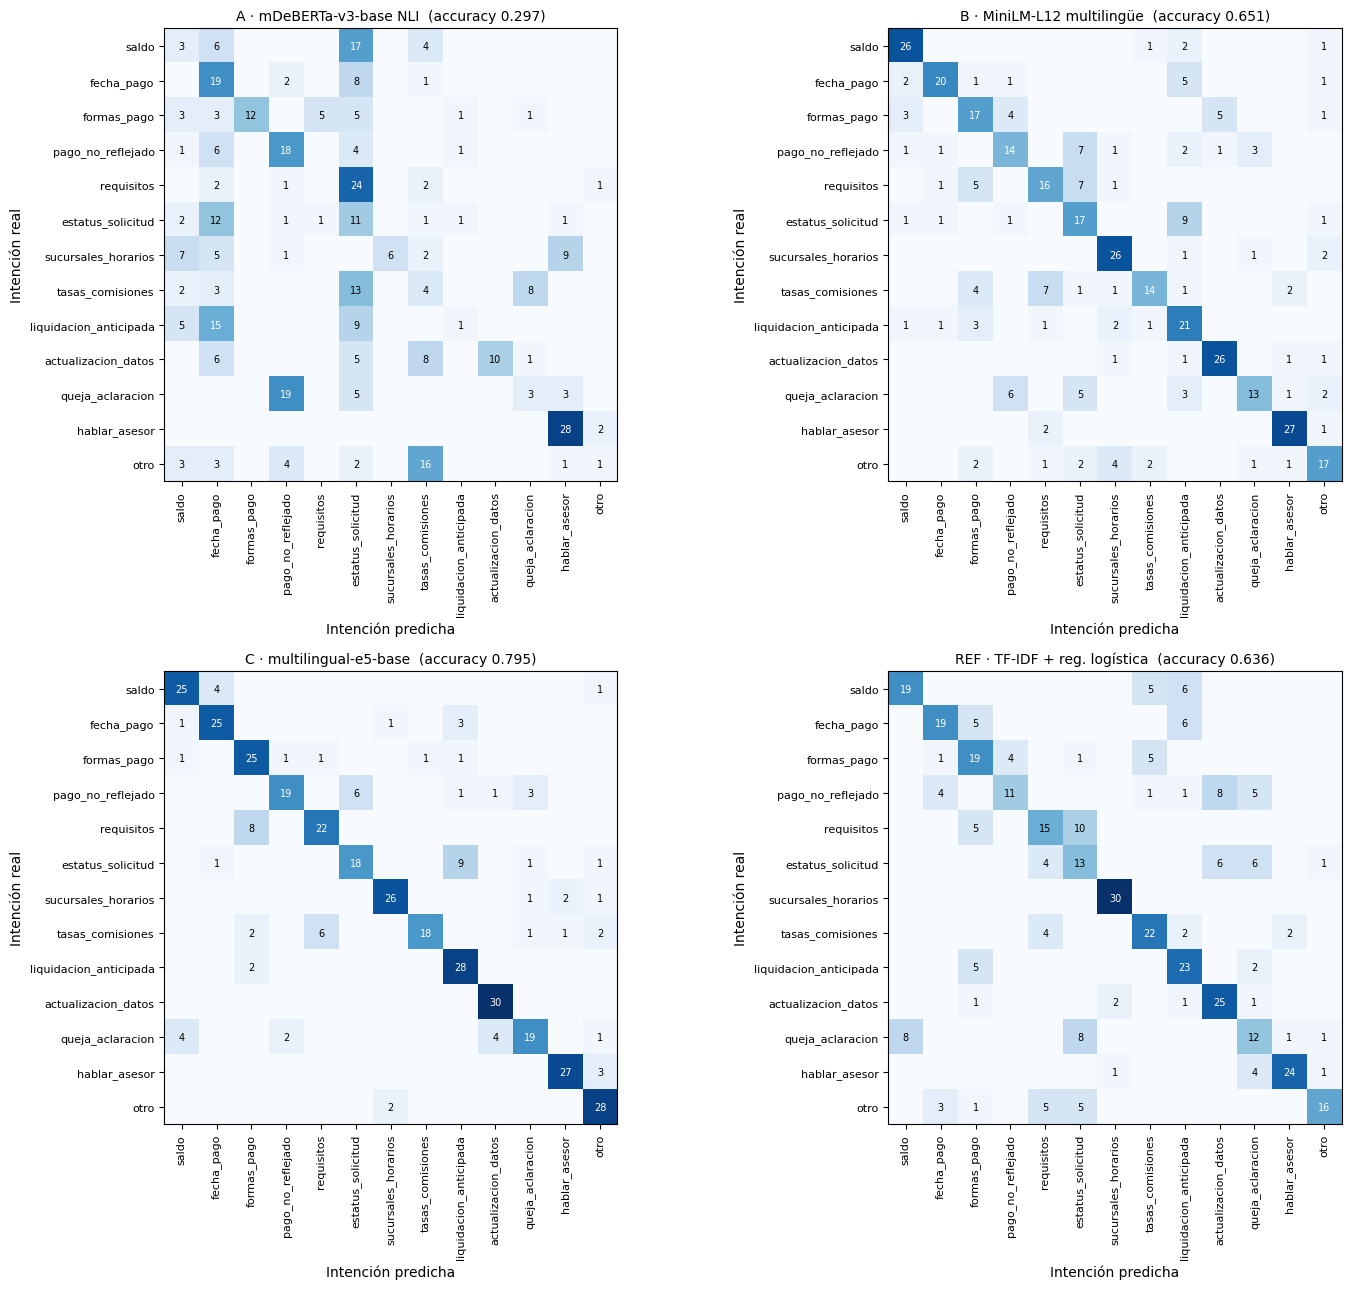

In [24]:
fig, ejes = plt.subplots(2, 2, figsize=(15, 13))
for eje, c in zip(ejes.ravel(), ORDEN):
    m = confusion_matrix(y["test"], PROBAS[c]["test"].argmax(axis=1), labels=list(range(len(ETIQUETAS))))
    eje.imshow(m, cmap="Blues", vmin=0, vmax=m.sum(axis=1).max())
    eje.set_xticks(range(len(ETIQUETAS))); eje.set_yticks(range(len(ETIQUETAS)))
    eje.set_xticklabels(ETIQUETAS, rotation=90, fontsize=8); eje.set_yticklabels(ETIQUETAS, fontsize=8)
    for i in range(len(ETIQUETAS)):
        for j in range(len(ETIQUETAS)):
            if m[i, j]:
                eje.text(j, i, m[i, j], ha="center", va="center", fontsize=7,
                         color="white" if m[i, j] > m.max() / 2 else "black")
    eje.set_title(f"{c} · {RESULTADOS[c]['modelo']}  (accuracy {RESULTADOS[c]['accuracy']:.3f})", fontsize=10)
    eje.set_xlabel("Intención predicha"); eje.set_ylabel("Intención real")
for eje in ejes.ravel()[len(ORDEN):]:
    eje.axis("off")
plt.tight_layout(); plt.savefig(DIR_RESULTADOS / "matrices_confusion.png", dpi=150); plt.show()

## 11. Robustez ante la forma de escribir
Accuracy en prueba según el tipo de variante. Mide cuánto se degrada cada modelo cuando el cliente escribe sin acentos, con abreviaturas o con errores de dedo.

In [25]:
variante = datos["test"]["tipo_variante"].to_numpy()
robustez = pd.DataFrame({c: pd.Series(PROBAS[c]["test"].argmax(axis=1) == y["test"]).groupby(variante).mean()
                         for c in ORDEN}).reindex(["original", "sin_acentos", "saludo_cierre", "abreviada", "errores_tecleo"])
robustez.index.name = "tipo_variante"
robustez.to_csv(DIR_RESULTADOS / "robustez_por_variante.csv", encoding="utf-8")
display(robustez.style.format("{:.3f}").background_gradient(cmap="Blues", vmin=0, vmax=1))

,A,B,C,REF
tipo_variante,,,,
original,0.282,0.756,0.833,0.654
sin_acentos,0.269,0.756,0.833,0.641
saludo_cierre,0.321,0.718,0.821,0.615
abreviada,0.359,0.500,0.744,0.654
errores_tecleo,0.256,0.526,0.744,0.615


## 12. Equilibrio entre precisión y eficiencia
Arriba y a la izquierda es mejor: más F1 con menos latencia. La línea vertical es el umbral de latencia del caso.

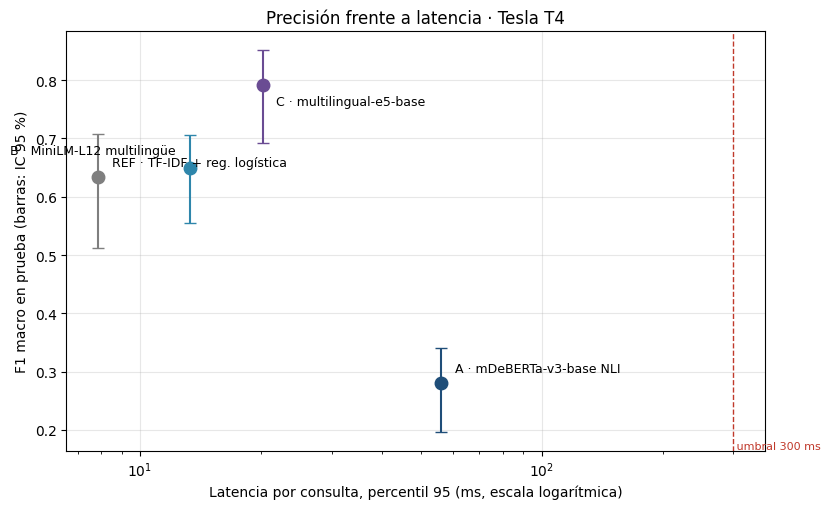

In [26]:
fig, eje = plt.subplots(figsize=(8.5, 5.2))
colores = {"A": "#1f4e79", "B": "#2e86ab", "C": "#6a4c93", "REF": "#7f7f7f"}
desplazamiento = {"A": (10, 8), "B": (-10, 10), "C": (10, -14), "REF": (10, 8)}
for c in ORDEN:
    r = RESULTADOS[c]
    lo, hi = r["f1_macro_ic95"]
    eje.errorbar(r["latencia_p95_ms"], r["f1_macro"], yerr=[[max(r["f1_macro"] - lo, 0)], [max(hi - r["f1_macro"], 0)]],
                 fmt="o", ms=9, color=colores[c], capsize=4)
    eje.annotate(f"{c} · {r['modelo']}", (r["latencia_p95_ms"], r["f1_macro"]), textcoords="offset points",
                 xytext=desplazamiento[c], fontsize=9, ha="left" if desplazamiento[c][0] > 0 else "right")
eje.axvline(UMBRALES["latencia_p95_ms_max"], color="#c0392b", ls="--", lw=1)
eje.text(UMBRALES["latencia_p95_ms_max"], eje.get_ylim()[0], f" umbral {UMBRALES['latencia_p95_ms_max']} ms",
         color="#c0392b", fontsize=8, va="bottom")
eje.set_xscale("log"); eje.set_xlabel("Latencia por consulta, percentil 95 (ms, escala logarítmica)")
eje.set_ylabel("F1 macro en prueba (barras: IC 95 %)")
eje.set_title(f"Precisión frente a latencia · {NOMBRE_GPU}")
eje.grid(alpha=0.3); plt.tight_layout()
plt.savefig(DIR_RESULTADOS / "precision_vs_latencia.png", dpi=150); plt.show()

## 13. Umbral de confianza: cuándo responde Cenzi y cuándo escala
Cenzi sólo responde si la probabilidad de la intención ganadora supera un umbral; por debajo, pasa la consulta a una persona. Subir el umbral mejora el acierto en lo que responde y reduce la proporción de consultas atendidas (cobertura).

El umbral de cada modelo se eligió en **validación** (el más bajo que alcanza 90 % de acierto con al menos 20 consultas respondidas) y aquí se comprueba en **prueba**.

,modelo,umbral_confianza,umbral_alcanza_objetivo_val,val_cobertura,val_acierto_respondidas,cobertura,acierto_respondidas,error_total,cumple_en_prueba
clave,,,,,,,,,
A,mDeBERTa-v3-base NLI,0.91,False,8.1%,85.7%,8.7%,73.5%,2.3%,False
B,MiniLM-L12 multilingüe,0.74,True,36.5%,90.5%,36.7%,94.4%,2.1%,False
C,multilingual-e5-base,0.39,True,53.8%,90.0%,61.0%,95.8%,2.6%,True
REF,TF-IDF + reg. logística,0.63,True,23.1%,90.0%,22.6%,90.9%,2.1%,False


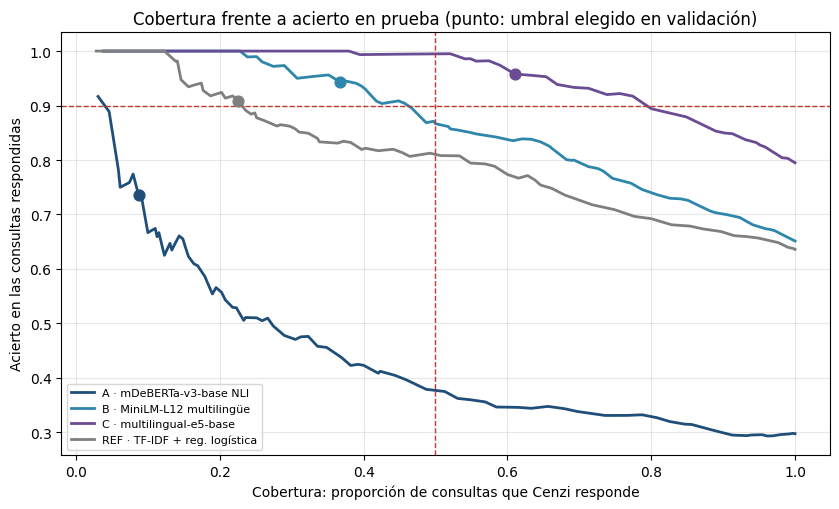

In [27]:
columnas_umbral = ["modelo", "umbral_confianza", "umbral_alcanza_objetivo_val", "val_cobertura",
                   "val_acierto_respondidas", "cobertura", "acierto_respondidas", "error_total"]
tabla_umbrales = tabla[columnas_umbral].copy()
tabla_umbrales["cumple_en_prueba"] = ((tabla["acierto_respondidas"] >= UMBRALES["acierto_respondidas_min"])
                                      & (tabla["cobertura"] >= UMBRALES["cobertura_min"])
                                      & (tabla["error_total"] <= UMBRALES["error_total_max"]))
tabla_umbrales.to_csv(DIR_RESULTADOS / "umbrales.csv", encoding="utf-8")
display(tabla_umbrales.style.format({k: "{:.1%}" for k in ("val_cobertura", "val_acierto_respondidas",
                                     "cobertura", "acierto_respondidas", "error_total")} | {"umbral_confianza": "{:.2f}"}))

fig, eje = plt.subplots(figsize=(8.5, 5.2))
curvas = []
for c in ORDEN:
    proba = PROBAS[c]["test"]; confianza, pred = proba.max(axis=1), proba.argmax(axis=1)
    xs, ys = [], []
    for u in np.round(np.arange(0.0, 1.0, 0.01), 2):
        resp = confianza >= u
        if resp.sum() < 10:
            break
        xs.append(resp.mean()); ys.append((pred[resp] == y["test"][resp]).mean())
        curvas.append({"clave": c, "umbral": u, "cobertura": xs[-1], "acierto_respondidas": ys[-1]})
    eje.plot(xs, ys, color=colores[c], lw=2, label=f"{c} · {RESULTADOS[c]['modelo']}")
    eje.scatter([RESULTADOS[c]["cobertura"]], [RESULTADOS[c]["acierto_respondidas"]], color=colores[c], s=60, zorder=3)
eje.axhline(UMBRALES["acierto_respondidas_min"], color="#c0392b", ls="--", lw=1)
eje.axvline(UMBRALES["cobertura_min"], color="#c0392b", ls="--", lw=1)
eje.set_xlabel("Cobertura: proporción de consultas que Cenzi responde"); eje.set_ylabel("Acierto en las consultas respondidas")
eje.set_title("Cobertura frente a acierto en prueba (punto: umbral elegido en validación)")
eje.legend(fontsize=8, loc="lower left"); eje.grid(alpha=0.3); plt.tight_layout()
plt.savefig(DIR_RESULTADOS / "cobertura_vs_acierto.png", dpi=150); plt.show()
pd.DataFrame(curvas).to_csv(DIR_RESULTADOS / "curvas_cobertura.csv", index=False, encoding="utf-8")

## 14. Selección del modelo
La regla se definió antes de medir y se aplica con los datos de **validación**, para no elegir con el mismo conjunto con el que después se reporta:

1. Son elegibles los modelos del Hub con latencia p95 dentro del umbral y que en validación alcanzan el acierto objetivo con la cobertura mínima.
2. Entre los elegibles gana el de mayor F1 macro en validación.
3. Si la diferencia con otro elegible es menor que el margen de empate, gana el de menos parámetros.

Si ningún modelo es elegible, se informa y se aplica la regla sobre los tres, sin recomendar su paso a producción.

In [28]:
candidatos = tabla.loc[[c for c in ("A", "B", "C") if c in tabla.index]].copy()
candidatos["cumple_latencia"] = candidatos["latencia_p95_ms"] <= UMBRALES["latencia_p95_ms_max"]
candidatos["cumple_calidad_val"] = ((candidatos["val_acierto_respondidas"] >= UMBRALES["acierto_respondidas_min"])
                                    & (candidatos["val_cobertura"] >= UMBRALES["cobertura_min"]))
candidatos["elegible"] = candidatos["cumple_latencia"] & candidatos["cumple_calidad_val"]
display(candidatos[["modelo", "val_f1_macro", "latencia_p95_ms", "cumple_latencia", "val_cobertura",
                    "val_acierto_respondidas", "cumple_calidad_val", "elegible", "parametros_millones"]])

HAY_ELEGIBLES = bool(candidatos["elegible"].any())
grupo = candidatos[candidatos["elegible"]] if HAY_ELEGIBLES else candidatos
empatados = grupo[grupo["val_f1_macro"] >= grupo["val_f1_macro"].max() - UMBRALES["empate_f1"]]
RECOMENDADO = empatados.sort_values("parametros_millones").index[0]

r = RESULTADOS[RECOMENDADO]
print(f"Modelo recomendado: {RECOMENDADO} · {r['modelo']}  ({r['hub_id']})")
if not HAY_ELEGIBLES:
    print("AVISO: ningún modelo cumple todos los umbrales en validación; es el mejor disponible, no una recomendación de producción.")
if len(empatados) > 1:
    print("Empate de F1 dentro del margen con:", ", ".join(c for c in empatados.index if c != RECOMENDADO), "→ se elige el de menos parámetros.")

,modelo,val_f1_macro,latencia_p95_ms,cumple_latencia,val_cobertura,val_acierto_respondidas,cumple_calidad_val,elegible,parametros_millones
clave,,,,,,,,,
A,mDeBERTa-v3-base NLI,0.301116,56.188701,True,0.080769,0.857143,False,False,278.811651
B,MiniLM-L12 multilingüe,0.636240,13.287063,True,0.365385,0.905263,False,False,117.653760
C,multilingual-e5-base,0.778467,20.200660,True,0.538462,0.900000,True,True,278.043648


Modelo recomendado: C · multilingual-e5-base  (intfloat/multilingual-e5-base)


## 15. Pipeline de inferencia del modelo recomendado
La función `clasificar` es el prototipo de Cenzi: recibe un texto y devuelve la intención, la confianza y la acción. Sólo entrega la respuesta aprobada si la confianza supera el umbral; en otro caso escala.

In [29]:
def clasificar(texto, clave=None):
    clave = clave or RECOMENDADO
    proba = PREDICTORES[clave]([texto])[0]
    i = int(proba.argmax()); intencion = ETIQUETAS[i]; confianza = float(proba[i])
    if confianza < RESULTADOS[clave]["umbral_confianza"]:
        accion, respuesta = "escalar", "Te comunico con una persona de atención a clientes para ayudarte mejor."
    else:
        accion, respuesta = ACCION_DE[intencion], RESPUESTA_DE[intencion]
    return {"texto": texto, "intencion": intencion, "confianza": round(confianza, 3), "accion": accion, "respuesta": respuesta}

ejemplos = [
    "oigan ya deposite desde el lunes y me sigue saliendo que debo",
    "kiero saber q papeles ocupo pa sacar un prestamo",
    "¿Hasta qué hora atienden los sábados?",
    "me urge hablar con alguien, nadie me contesta",
    "¿venden boletos de avión?",
]
display(pd.DataFrame([clasificar(t) for t in ejemplos]))

,texto,intencion,confianza,accion,respuesta
0,oigan ya deposite desde el lunes y me sigue saliendo que debo,pago_no_reflejado,0.256,escalar,Te comunico con una persona de atención a clientes para ayudarte mejor.
1,kiero saber q papeles ocupo pa sacar un prestamo,requisitos,0.298,escalar,Te comunico con una persona de atención a clientes para ayudarte mejor.
2,¿Hasta qué hora atienden los sábados?,sucursales_horarios,0.915,responder,Consulta la sucursal más cercana y su horario en el localizador de nuestro sitio web y...
3,"me urge hablar con alguien, nadie me contesta",hablar_asesor,0.620,escalar,Con gusto te comunicamos con una persona de atención a clientes. En un momento te atie...
4,¿venden boletos de avión?,otro,0.659,pedir_aclaracion,"Puedo ayudarte con dudas sobre tu crédito: saldo, pagos, requisitos, sucursales y más...."


## 16. Guardado de resultados
Se guardan las predicciones, el entorno de ejecución y un resumen en `results/`, y se descarga todo en `resultados.zip`.

In [32]:
predicciones = datos["test"][["id", "texto", "intencion", "frase_base", "tipo_variante"]].copy()
for c in ORDEN:
    predicciones[f"pred_{c}"] = [ETIQUETAS[i] for i in PROBAS[c]["test"].argmax(axis=1)]
    predicciones[f"conf_{c}"] = PROBAS[c]["test"].max(axis=1).round(4)
predicciones.to_csv(DIR_RESULTADOS / "predicciones_test.csv", index=False, encoding="utf-8")

entorno = {"fecha_utc": time.strftime("%Y-%m-%d %H:%M:%S", time.gmtime()), "dispositivo": DISPOSITIVO,
           "gpu": NOMBRE_GPU, "memoria_gpu_gb": MEMORIA_GPU_GB, "sistema": platform.platform(),
           "semilla": SEMILLA, "versiones": VERSIONES,
           "protocolo_latencia": {"calentamiento": N_CALENTAMIENTO, "mediciones": N_LATENCIA, "lote": 1},
           "max_tokens": MAX_TOKENS, "lote_embeddings": LOTE_EMBEDDINGS, "lote_nli": LOTE_NLI}
(DIR_RESULTADOS / "entorno.json").write_text(json.dumps(entorno, indent=2, ensure_ascii=False), encoding="utf-8")

resumen_json = {"recomendado": RECOMENDADO, "hay_elegibles": HAY_ELEGIBLES, "umbrales": UMBRALES,
                "plantilla_nli": PLANTILLA_ELEGIDA if "A" in RESULTADOS else None,
                "tamano_particiones": {p: len(X[p]) for p in X}, "modelos": RESULTADOS}
(DIR_RESULTADOS / "resumen.json").write_text(
    json.dumps(resumen_json, indent=2, ensure_ascii=False, default=lambda o: o.item() if hasattr(o, "item") else str(o)),
    encoding="utf-8")

shutil.make_archive("resultados", "zip", DIR_RESULTADOS)
print("Archivos en results/:"); [print("  ", p.name) for p in sorted(DIR_RESULTADOS.iterdir())]
try:
    from google.colab import files
    files.download("resultados.zip")
except ImportError:
    print("resultados.zip creado en", Path("resultados.zip").resolve())

Archivos en results/:
   cobertura_vs_acierto.png
   curvas_cobertura.csv
   entorno.json
   matrices_confusion.png
   metricas_por_clase.csv
   precision_vs_latencia.png
   predicciones_test.csv
   resumen.json
   robustez_por_variante.csv
   tabla_comparativa.csv
   umbrales.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 17. Conclusiones
La celda siguiente resume la corrida con sus propios números.

In [31]:
r = RESULTADOS[RECOMENDADO]; ref = RESULTADOS["REF"]
print(f"Entorno: {NOMBRE_GPU} · transformers {VERSIONES['transformers']} · sentence-transformers {VERSIONES['sentence_transformers']}\n")
for c in ORDEN:
    x = RESULTADOS[c]
    print(f"{c:>3} · {x['modelo']:<26} F1 macro {x['f1_macro']:.3f} · accuracy {x['accuracy']:.3f} · "
          f"p95 {x['latencia_p95_ms']:7.1f} ms · {x['parametros_millones']:6.1f} M parámetros")
print(f"\nModelo recomendado: {RECOMENDADO} · {r['modelo']} ({r['hub_id']})")
print(f"  · F1 macro en prueba {r['f1_macro']:.3f} (IC 95 %: {r['f1_macro_ic95'][0]:.3f}–{r['f1_macro_ic95'][1]:.3f}); "
      f"{r['f1_macro'] - ref['f1_macro']:+.3f} frente a la línea base TF-IDF.")
print(f"  · Latencia p95 {r['latencia_p95_ms']:.1f} ms frente a un umbral de {UMBRALES['latencia_p95_ms_max']} ms.")
print(f"  · Con umbral de confianza {r['umbral_confianza']:.2f}: responde {r['cobertura']:.1%} de las consultas con "
      f"{r['acierto_respondidas']:.1%} de acierto; respuestas equivocadas {r['error_total']:.1%} del total.")
cumple = (r["acierto_respondidas"] >= UMBRALES["acierto_respondidas_min"] and r["cobertura"] >= UMBRALES["cobertura_min"]
          and r["error_total"] <= UMBRALES["error_total_max"] and r["latencia_p95_ms"] <= UMBRALES["latencia_p95_ms_max"])
print(f"  · Umbrales del caso en prueba: {'SE CUMPLEN' if cumple else 'NO SE CUMPLEN TODOS'}.")
print("\nLímite de estas cifras: el dataset es sintético. Antes de producción hay que repetir la evaluación con consultas reales.")

Entorno: Tesla T4 · transformers 5.18.0 · sentence-transformers 5.7.0

  A · mDeBERTa-v3-base NLI       F1 macro 0.281 · accuracy 0.297 · p95    56.2 ms ·  278.8 M parámetros
  B · MiniLM-L12 multilingüe     F1 macro 0.649 · accuracy 0.651 · p95    13.3 ms ·  117.7 M parámetros
  C · multilingual-e5-base       F1 macro 0.791 · accuracy 0.795 · p95    20.2 ms ·  278.0 M parámetros
REF · TF-IDF + reg. logística    F1 macro 0.634 · accuracy 0.636 · p95     7.9 ms ·    0.1 M parámetros

Modelo recomendado: C · multilingual-e5-base (intfloat/multilingual-e5-base)
  · F1 macro en prueba 0.791 (IC 95 %: 0.692–0.851); +0.157 frente a la línea base TF-IDF.
  · Latencia p95 20.2 ms frente a un umbral de 300 ms.
  · Con umbral de confianza 0.39: responde 61.0% de las consultas con 95.8% de acierto; respuestas equivocadas 2.6% del total.
  · Umbrales del caso en prueba: SE CUMPLEN.

Límite de estas cifras: el dataset es sintético. Antes de producción hay que repetir la evaluación con consultas rea